# Support Vector Machines and Kernels

![SVM.png](Assets/SVM.png)

# Цели обучения
- Применить метод опорных векторов (SVM) — популярный алгоритм, используемый для задач классификации
- Распознать сходство SVM с логистической регрессией
- Вычислить функцию потерь для SVM
- Применить регуляризацию в SVM и изучить советы по получению нелинейной классификации с помощью SVM

## Введение
В этих упражнениях мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (от 3 до 9, где наивысший балл означает лучшее качество) и цвет (красное или белое). Имя файла: `Wine_Quality_Data.csv`.

In [ ]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler

from sklearnex import patch_sklearn
patch_sklearn()

Intel(R) Extension for Scikit-learn* enabled (https://github.com/intel/scikit-learn-intelex)


## Вопрос 1
* Импорт данных.
* Создайте целевую переменную `y` как колонка 1/0, где 1 означает красное вино.
* Создайте парный график для набора данных.
* Создайте диаграмму столбцов, которая отображает корреляцию между каждым колонкой и `y`.
* Выберите 2 поля с наибольшей корреляцией (используя значения абсолютной корреляции) и создайте `X`.
* Используйте MinMaxScaler для масштабирования `X` Обратите внимание, что вывод будет np.array. Сделайте его снова DataFrame и соответственно переименуйте столбцы.

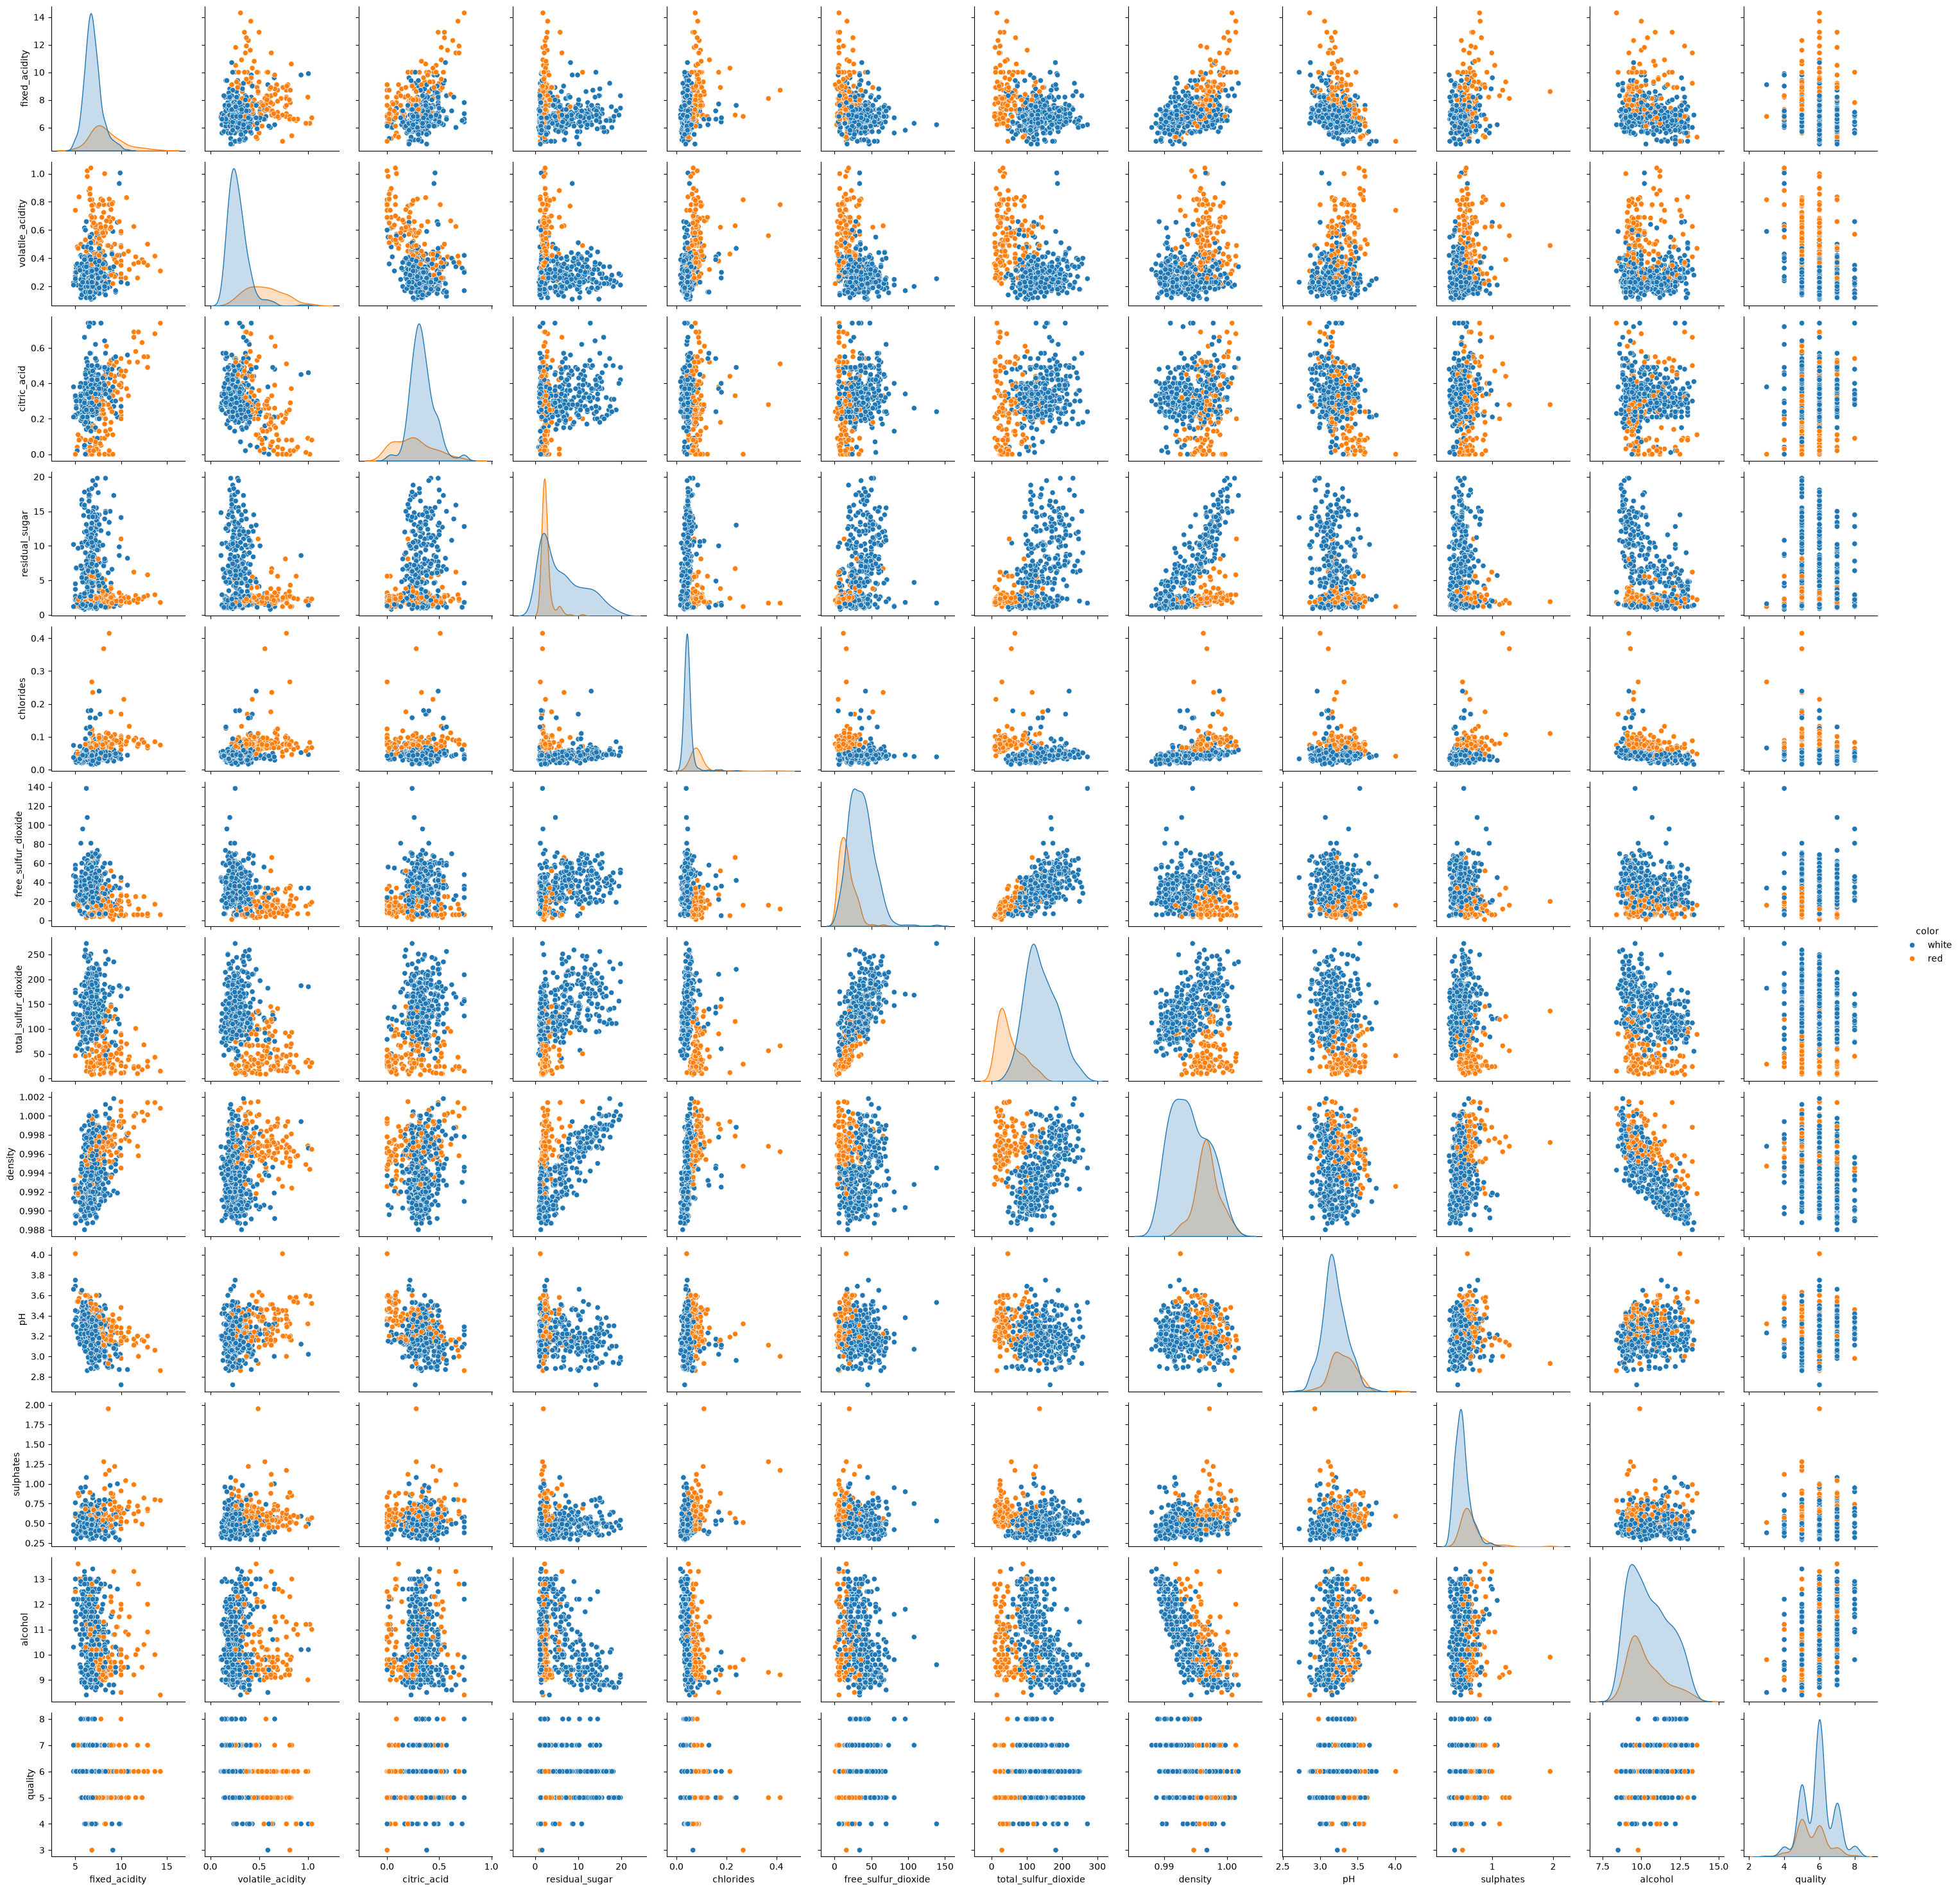

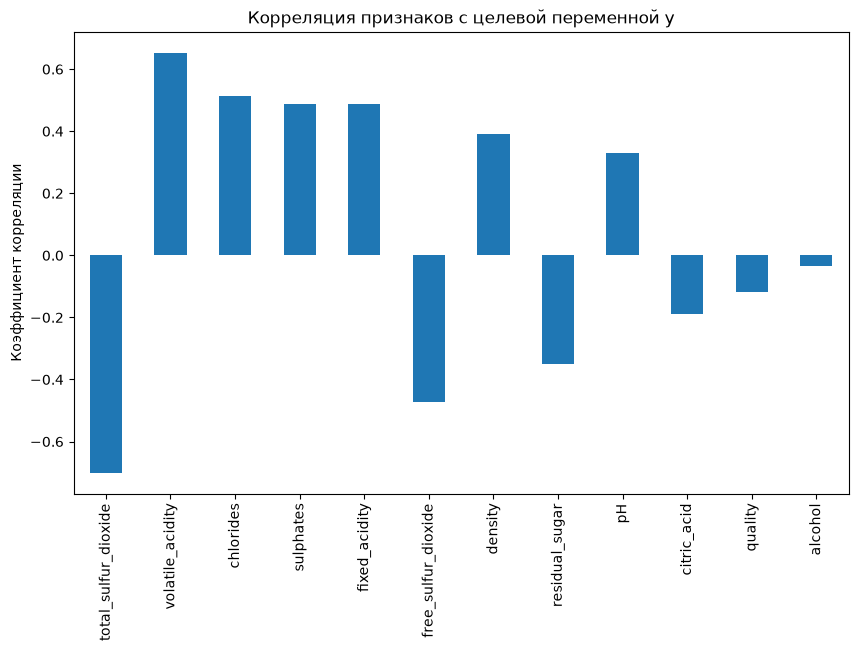

Выбранные признаки: ['total_sulfur_dioxide', 'volatile_acidity']
Первые 5 строк масштабированного X:
   total_sulfur_dioxide  volatile_acidity
0              0.064516          0.413333
1              0.140553          0.533333
2              0.110599          0.453333
3              0.124424          0.133333
4              0.064516          0.413333


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# 1. Импорт данных
# Предполагается, что файл Wine_Quality_Data.csv находится в рабочей директории
df = pd.read_csv('Wine_Quality_Data.csv')

# 2. Создание целевой переменной y (1 = красное вино, 0 = белое)
y = (df['color'] == 'red').astype(int)

# 3. Создание парного графика (Pairplot) для набора данных
# Для ускорения построения возьмем случайную выборку, так как данных много
sample_df = df.sample(n=500, random_state=42)
sns.pairplot(sample_df, hue='color')
plt.show()

# 4. Диаграмма столбцов для отображения корреляции между каждой колонкой и y
# Сначала объединим признаки и целевую переменную
df_corr = df.drop(columns=['color']).copy()
df_corr['y'] = y

# Вычисляем корреляцию только с колонкой 'y' и сортируем по модулю
correlations = df_corr.corr()['y'].drop('y').sort_values(key=abs, ascending=False)

plt.figure(figsize=(10, 6))
correlations.plot(kind='bar')
plt.title('Корреляция признаков с целевой переменной y')
plt.ylabel('Коэффициент корреляции')
plt.show()

# 5. Выбор 2 полей с наибольшей корреляцией (по абсолютному значению)
# Берем первые два признака из отсортированного списка
top_2_features = correlations.index[:2].tolist()
print(f"Выбранные признаки: {top_2_features}")

X = df[top_2_features].copy()

# 6. Использование MinMaxScaler для масштабирования X
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Возвращаем DataFrame и переименовываем столбцы обратно (как указано в задании)
X = pd.DataFrame(X_scaled, columns=top_2_features, index=df.index)

print("Первые 5 строк масштабированного X:")
print(X.head())

## Вопрос 2

Цель этого вопроса - посмотреть на границу принятия решения классификатора LinearSVC для данного набора данных. Ознакомьтесь с [этим примером](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) в документации sklearn.

* Установите классификатор линейной векторной машины поддержки на `X` , `y`.
* Выберите 300 образцов из `X`. Получите соответствующее значение `y`. Сохраните их в переменных `X_color` и `y_color`. Это связано с тем, что оригинальный набор данных слишком велик и создает переполненный график.
* Измените `y_color` таким образом, чтобы вместо 1 было указано значение «красный», а вместо 0 - «желтый».
* Рассеянный график для столбцов X_color. Используйте аргумент ключевого слова "color=y_color" для отображения кода цвета.
* Используйте фрагмент кода ниже, чтобы нарисовать поверхность решения в цветной форме.

`python
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T
y_grid_predictions = *[ВАША МОДЕЛЬ]*. predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
`

Не стесняйтесь экспериментировать с различными вариантами параметров для LinearSVC и просмотреть границы принятия решения.

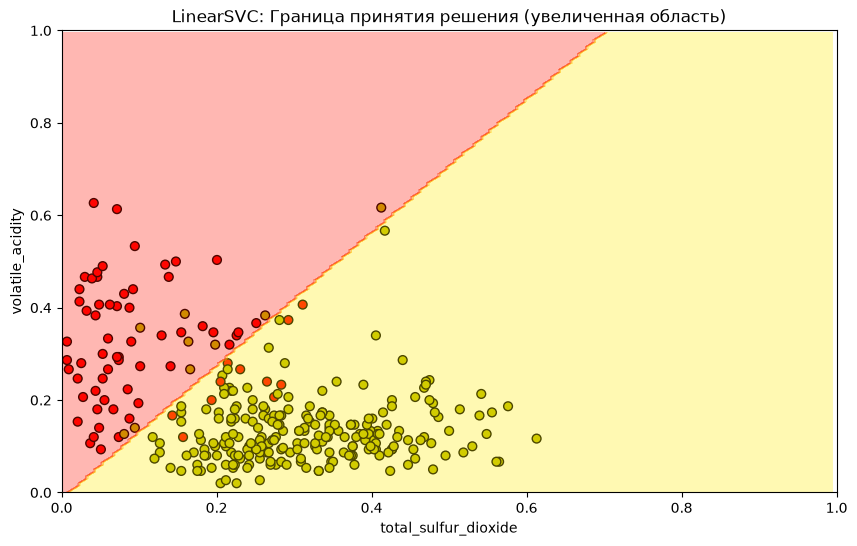

In [3]:
from sklearn.svm import LinearSVC

# 1. Установка классификатора и обучение на X и y
# Для наглядности возьмем только 2 признака (X уже содержит 2 столбца)
model = LinearSVC(random_state=42)
model.fit(X, y)

# 2. Выбор 300 образцов из X и y
# Используем случайную выборку для графика, чтобы избежать переполнения
X_sample = X.sample(n=300, random_state=42)
y_sample = y.loc[X_sample.index]

# 3. Изменение цвета: 1 - красный, 0 - желтый
# В matplotlib 'r' = red, 'y' = yellow
colors = ['y' if val == 0 else 'r' for val in y_sample]

# 4. Рассеянный график
plt.figure(figsize=(10, 6))
plt.scatter(X_sample.iloc[:, 0], X_sample.iloc[:, 1], c=colors, edgecolors='k', s=40)
plt.xlabel(X_sample.columns[0])
plt.ylabel(X_sample.columns[1])
plt.title('LinearSVC: Граница принятия решения (увеличенная область)')

# 5. Использование фрагмента кода ниже для нанесения поверхности решения
# ВАЖНО: В фрагменте из задания X_color и y_color нужно заменить на X_sample и y_sample
# и убедиться, что модель обучена (переменная 'model')
xx, yy = np.meshgrid(np.arange(0, 1, .005), np.arange(0, 1, .005))
# Создаем сетку для предсказания
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)
Z = model.predict(grid)
Z = Z.reshape(xx.shape)

# Наносим контур
plt.contourf(xx, yy, Z, cmap=plt.cm.autumn_r, alpha=.3)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()

# Примечание: Вы можете экспериментировать с параметром C в LinearSVC(C=...)
# для изменения границы решения.

## Вопрос 3

Давайте теперь развернем гауссовское ядро SVC и посмотрим, как изменяется граница решения.

* Объедините фрагменты кода в вопросе 2 в одну функцию, которая использует оценщика `X` и `y`, и создаст окончательный график с границей решения. Этапы:
    <ol>
     <li> подходящая модель
     <li> получить выборку 300 записей из X и соответствующих у
     <li> создать сетку, предсказать, составить график с помощью ax.contourf
     <li> добавить на рассеянный график
    </ol>
* После копирования и вставки кода убедитесь, что готовая функция использует ваш входной `оценщик` а не созданную вами модель LinearSVC.
* Для следующих значений `gamma` создайте Gaussian Kernel SVC и нарисуйте границу решения.  
`gammas = [.5, 1, 2, 10]`
* Удерживая `gamma` постоянную, для различных значений `C`, нарисуйте границу решения. Вы можете попробовать  
`Cs = [.1, 1, 10]>

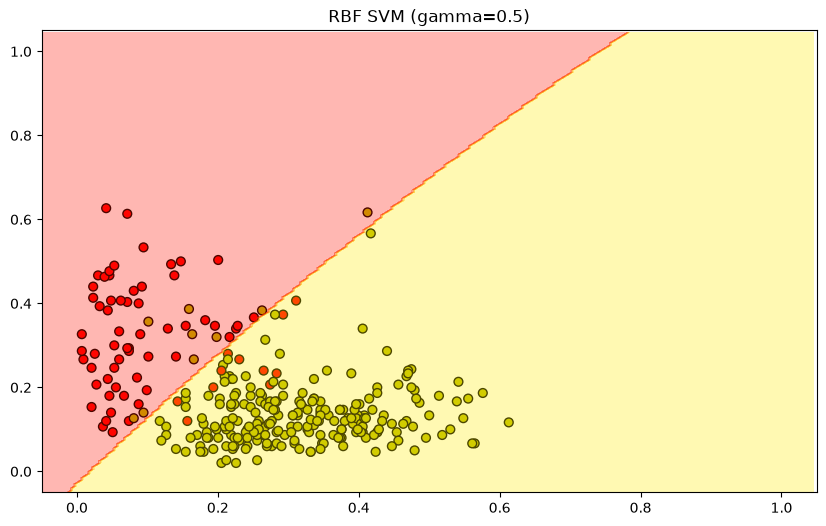

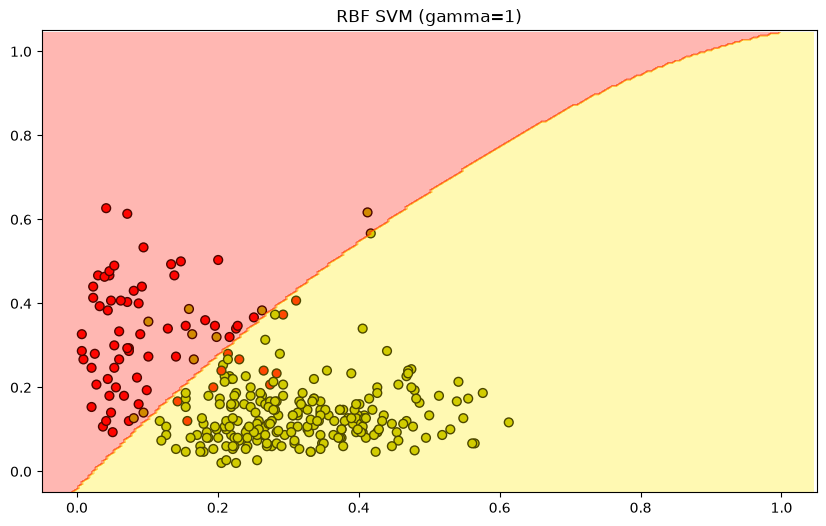

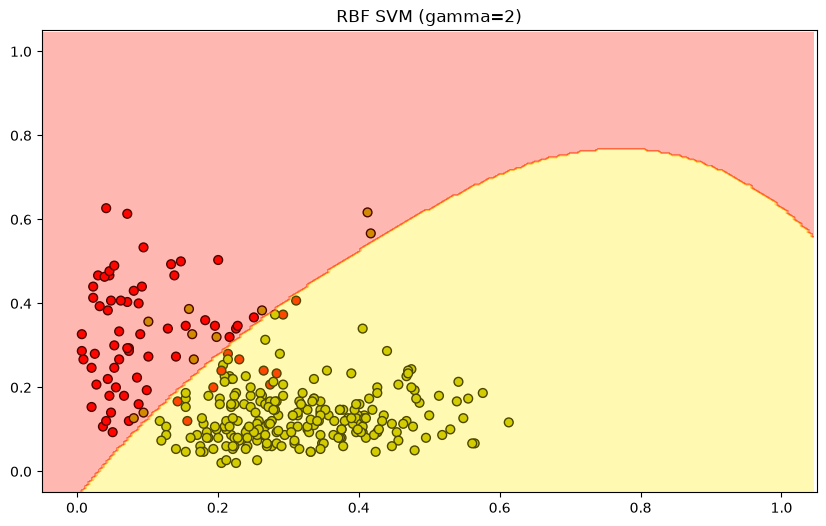

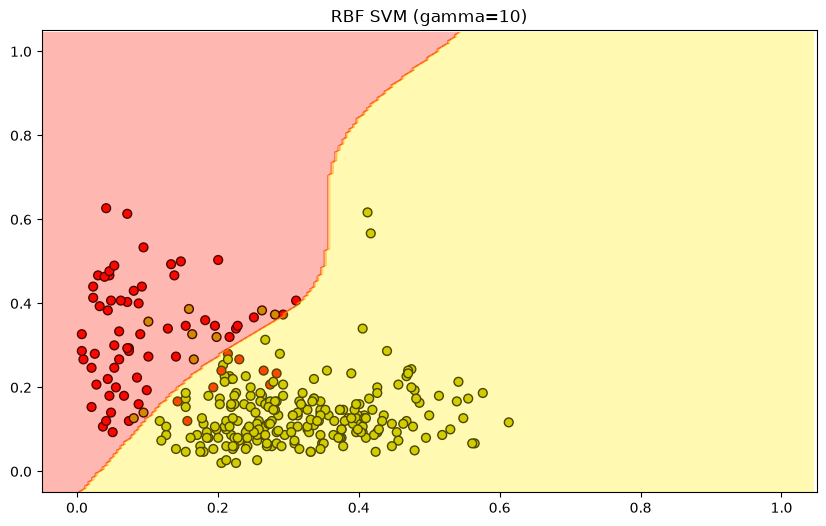

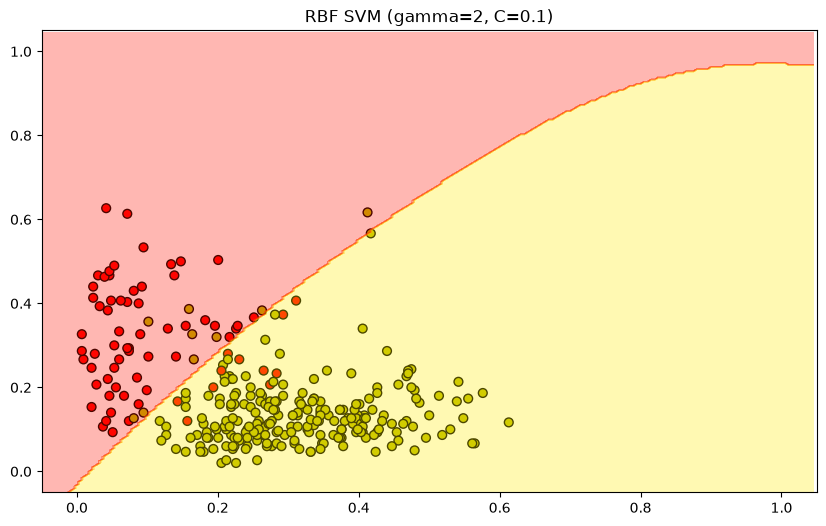

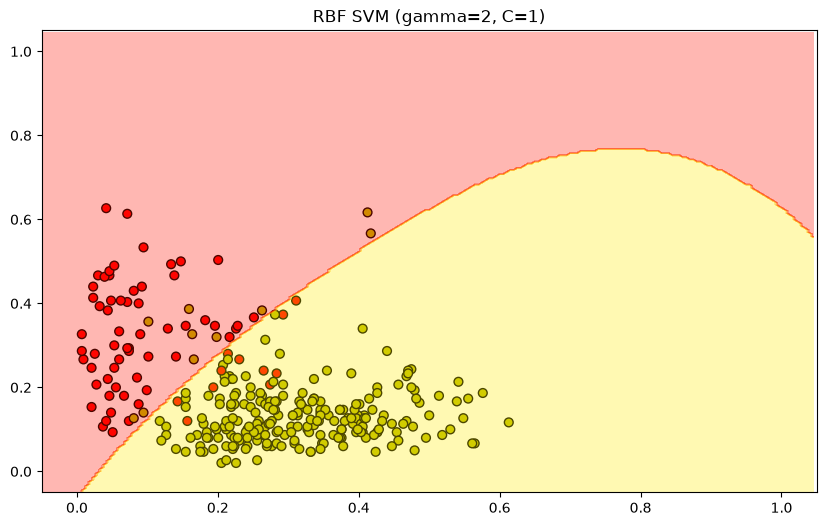

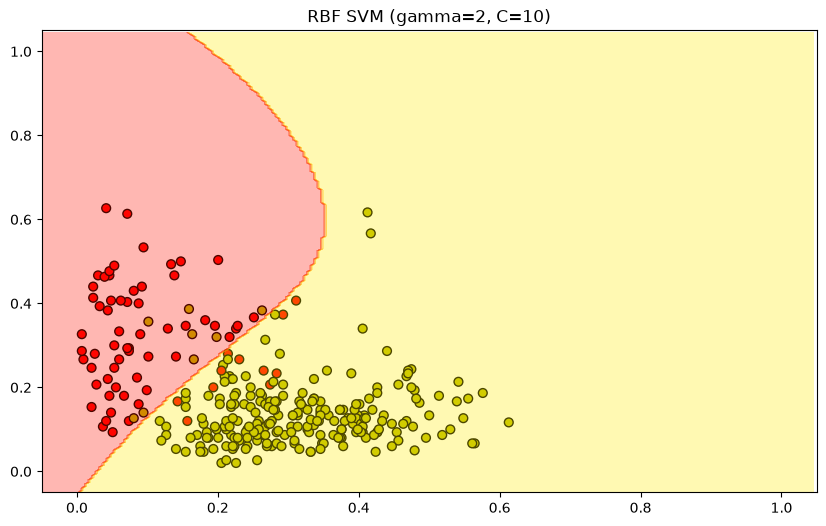

In [4]:
from sklearn.svm import SVC

def plot_decision_boundary(estimator, X, y, title="Decision Boundary"):
    """
    Функция для обучения модели и отрисовки границы решения.
    estimator: модель sklearn
    X: признаки (DataFrame)
    y: целевая переменная (Series)
    """
    # 1. Подходящая модель
    estimator.fit(X, y)
    
    # 2. Получить выборку 300 записей из X и соответствующих y
    # Используем .sample для случайного выбора
    X_subset = X.sample(n=300, random_state=42)
    y_subset = y.loc[X_subset.index]
    
    # 3. Создать сетку, предсказать, составить график с помощью ax.contourf
    x_min, x_max = X.iloc[:, 0].min() - 0.05, X.iloc[:, 0].max() + 0.05
    y_min, y_max = X.iloc[:, 1].min() - 0.05, X.iloc[:, 1].max() + 0.05
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.005),
                         np.arange(y_min, y_max, 0.005))
    
    # Создаем датафрейм для предсказания (чтобы избежать предупреждений о названиях колонок)
    grid_df = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)
    Z = estimator.predict(grid_df)
    Z = Z.reshape(xx.shape)
    
    # 4. Добавить на рассеянный график
    plt.figure(figsize=(10, 6))
    colors = ['y' if val == 0 else 'r' for val in y_subset]
    plt.scatter(X_subset.iloc[:, 0], X_subset.iloc[:, 1], c=colors, edgecolors='k', s=40)
    plt.contourf(xx, yy, Z, cmap=plt.cm.autumn_r, alpha=.3)
    plt.title(title)
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.show()

# --- Тестирование гауссова ядра (RBF SVM) ---

# Для следующих значений gamma создайте Gaussian Kernel SVC и нарисуйте границу
gammas = [.5, 1, 2, 10]
for gamma in gammas:
    # SVC с RBF ядром (по умолчанию kernel='rbf')
    svc_rbf = SVC(kernel='rbf', gamma=gamma)
    plot_decision_boundary(svc_rbf, X, y, title=f"RBF SVM (gamma={gamma})")

# --- Удерживая gamma постоянной, для различных значений C ---
# Возьмем, например, gamma = 2 (можно попробовать другое)
fixed_gamma = 2
Cs = [.1, 1, 10]

for C in Cs:
    svc_c = SVC(kernel='rbf', gamma=fixed_gamma, C=C)
    plot_decision_boundary(svc_c, X, y, title=f"RBF SVM (gamma={fixed_gamma}, C={C})")

## Вопрос 4

В этом вопросе мы сравним время установки между SVC и Nystroem с ядром rbf.  
<br><br>
Jupyter Notebooks предоставляет полезную магическую функцию **`%timeit`** которая выполняет строку и отпечатывает время, необходимое для установки. Если вы введете **`%timeit`** в начале ячейки, то она запустит всю ячейку и отобразит время выполнения.

* Повторно загрузите данные о качестве вина, если вы внесли изменения в оригинал.
* Создайте `y` из data.color и `X` из остальных столбцов.
* Используйте `%%timeit` чтобы получить время для настройки SVC с ядром rbf.
* Используйте `%%timeit` для получения времени для следующего: упорядочите данные с помощью Nystroem, а затем встроите SGD-классификатор.

Nystroem+SGD потребуется гораздо меньше времени для установки. Эта разница будет более выраженной, если набор данных был больше.

* Сделайте 5 копий X и свяжите их
* Сделайте 5 копий у и свяжите их
* Сравните время, необходимое для соответствия обоим методам выше.

In [6]:
import pandas as pd
import numpy as np
import time
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.kernel_approximation import Nystroem
from sklearn.preprocessing import MinMaxScaler

# 1. Повторно загружаем данные
df = pd.read_csv('Wine_Quality_Data.csv')

# 2. Создаем y из data.color и X из остальных столбцов
y = (df['color'] == 'red').astype(int)
X = df.drop(columns=['color'])

# Масштабируем данные
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print("--- Сравнение на исходном наборе данных ---")

# 3. Время для SVC с ядром rbf
start = time.time()
SVC(kernel='rbf').fit(X_scaled, y)
print(f"Время обучения SVC (RBF): {time.time() - start:.4f} секунд")

# 4. Время для Nystroem + SGDClassifier
start = time.time()
feature_map_nystroem = Nystroem(random_state=42)
X_nystroem = feature_map_nystroem.fit_transform(X_scaled)
SGDClassifier(random_state=42).fit(X_nystroem, y)
print(f"Время обучения Nystroem + SGDClassifier: {time.time() - start:.4f} секунд")


print("\n--- Сравнение на увеличенном наборе данных (5 копий) ---")

# ИСПРАВЛЕНИЕ ОШИБКИ: 
# X_scaled - это numpy array. np.tile повторит его 5 раз.
# (Если бы мы использовали pd.concat, нам пришлось бы сначала сделать X_scaled_df = pd.DataFrame(X_scaled))
X_large = np.tile(X_scaled, (5, 1)) 
y_large = np.tile(y, 5)

# Сравниваем время на больших данных
print("Время обучения SVC (RBF) на 5 копиях:")
start = time.time()
SVC(kernel='rbf').fit(X_large, y_large)
print(f"{time.time() - start:.4f} секунд")

print("\nВремя обучения Nystroem + SGDClassifier на 5 копиях:")
start = time.time()
# Для больших данных создаем новый маппер Nystroem
feature_map_nystroem_large = Nystroem(random_state=42)
X_large_nystroem = feature_map_nystroem_large.fit_transform(X_large)
SGDClassifier(random_state=42).fit(X_large_nystroem, y_large)
print(f"{time.time() - start:.4f} секунд")

--- Сравнение на исходном наборе данных ---
Время обучения SVC (RBF): 0.1104 секунд
Время обучения Nystroem + SGDClassifier: 0.0549 секунд

--- Сравнение на увеличенном наборе данных (5 копий) ---
Время обучения SVC (RBF) на 5 копиях:
1.5124 секунд

Время обучения Nystroem + SGDClassifier на 5 копиях:
0.2002 секунд
